# code_187 · Evaluate the procedure that did the selecting

**Book:** section 35.5. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_35_GUIDE.md), [execution evidence](../CHAPTER_35_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_187).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or field causal conclusions. Configuration spaces, data roles, selection information and resource accounting are explicit. Generated records do not establish field performance or intervention validity. Original scoped mechanisms are identified separately from native library models.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=7687;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 7687


<a id="nested-selection-and-refitting"></a>
 ## Fit inside inner boundaries and assess outside them
 Generate 160 independent buildings with four records each;120 source buildings enter nested selection and 40 final buildings stay locked. Features include missing values and shared building variation. Three outer GroupKFold splits fit 80 source buildings and assess 40; each outer training subset uses three inner grouped folds. Four declared boosting recipes cross depth 2/5 and rate 0.05/0.15. Each inner fit trains 40 trees with automatic early stopping disabled, evaluating staged checkpoints 5/15/40 on that inner validation fold. All 40 trees count as spent computation; selecting a stopping checkpoint retrospectively is not a claimed early-saving implementation. Source-only median imputation is fitted independently in every inner split.

 Select recipe/checkpoint by lowest mean inner validation MSE. Refit on the entire outer training subset at that fixed tree count, then score its outer assessment buildings once. Outer outcomes never choose their own settings. After reporting the outer procedure scores, rerun the same inner selection on all 120 source buildings, refit the resulting fixed recipe/checkpoint on those 480 records and assess the 40 final buildings once. No final-label stopping. The inner best score and outer score have different information roles and training sizes; their difference is not attributable solely to selection bias.


,outer_fold,selected_recipe,selected_trees,inner_selected_MSE,outer_MSE,outer_train_buildings,outer_assessment_buildings
0,0,"{'depth': 5, 'rate': 0.15}",40,0.968511,0.768361,80,40
1,1,"{'depth': 5, 'rate': 0.15}",40,0.894464,0.849647,80,40
2,2,"{'depth': 5, 'rate': 0.15}",40,0.927318,0.952379,80,40


Fixed refit: {'depth': 5, 'rate': 0.15} 40 trees; final MSE 0.7155853764385919


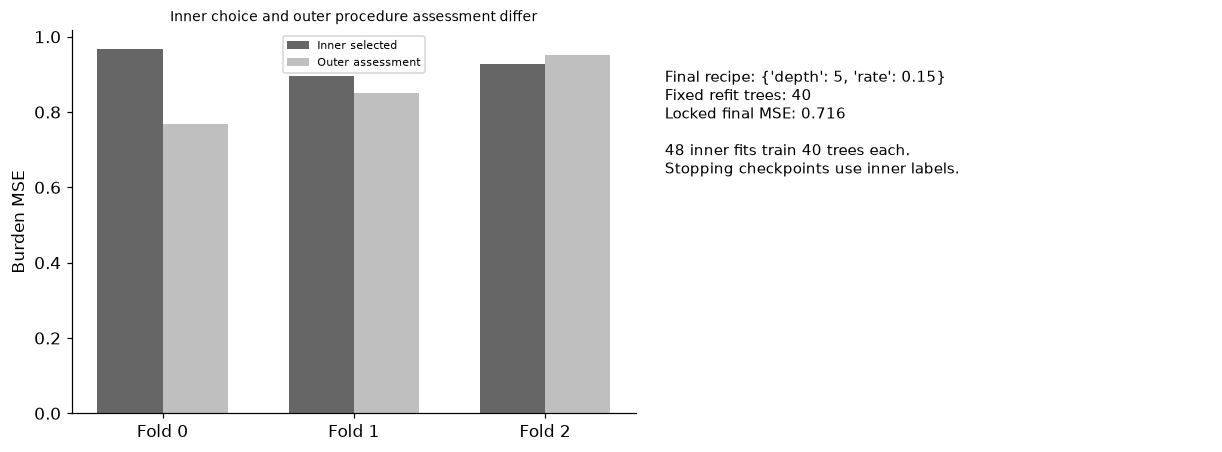

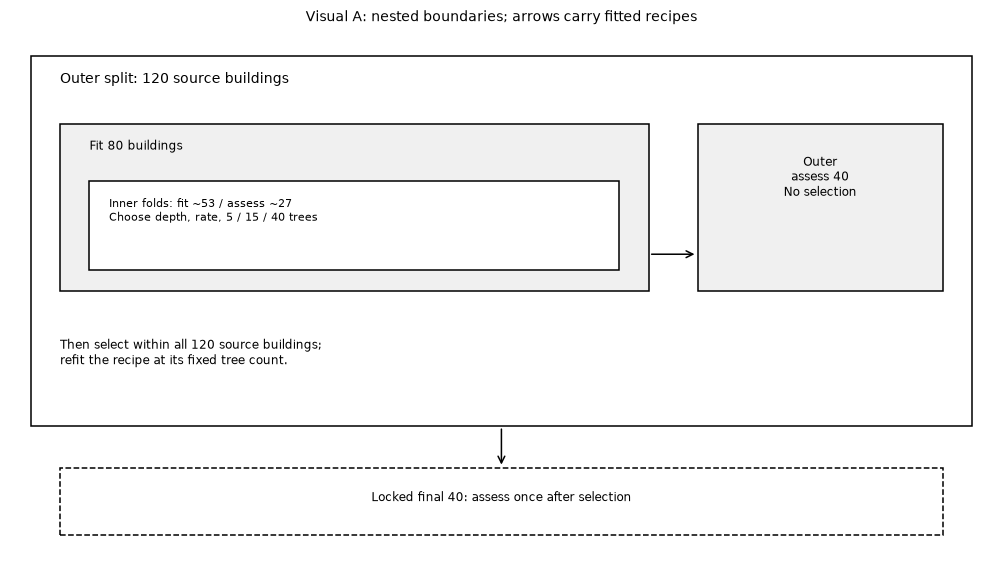

In [2]:
from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
group=np.repeat(np.arange(160),4);X=rng.normal(size=(640,6));X[:,:2]+=rng.normal(scale=.7,size=(160,2))[group];Y=np.sin(1.5*X[:,0])+.6*X[:,1]*X[:,2]-.5*X[:,3]+rng.normal(scale=.5,size=160)[group]+rng.normal(scale=.25,size=640);X[rng.random(X.shape)<.06]=np.nan;source=np.flatnonzero(group<120);final=np.flatnonzero(group>=120);specs=[{'depth':d,'rate':r} for d in [2,5] for r in [.05,.15]];checkpoints=[5,15,40];fit_audit=[]
def choose(indices):
    losses=np.zeros((4,3,3));splits=list(GroupKFold(3).split(X[indices],Y[indices],group[indices]))
    for fold,(left,right) in enumerate(splits):
        train=indices[left];val=indices[right];assert set(group[train]).isdisjoint(set(group[val]));imp=SimpleImputer(strategy='median').fit(X[train]);np.testing.assert_allclose(imp.statistics_,np.nanmedian(X[train],axis=0));tr=imp.transform(X[train]);va=imp.transform(X[val])
        for j,c in enumerate(specs):
            m=HistGradientBoostingRegressor(max_iter=40,max_depth=c['depth'],learning_rate=c['rate'],min_samples_leaf=12,early_stopping=False,random_state=SEED).fit(tr,Y[train]);pred={i:p for i,p in enumerate(m.staged_predict(va),1) if i in checkpoints}
            for k,n in enumerate(checkpoints):losses[j,k,fold]=np.mean((pred[n]-Y[val])**2)
            fit_audit.append({'role':'inner','train_buildings':len(set(group[train])),'validation_buildings':len(set(group[val])),'trees_spent':40})
    mean=losses.mean(2);j,k=np.unravel_index(np.argmin(mean),mean.shape);return int(j),checkpoints[k],float(mean[j,k]),mean.tolist()
def refit(indices,j,n):
    imp=SimpleImputer(strategy='median').fit(X[indices]);m=HistGradientBoostingRegressor(max_iter=n,max_depth=specs[j]['depth'],learning_rate=specs[j]['rate'],min_samples_leaf=12,early_stopping=False,random_state=SEED).fit(imp.transform(X[indices]),Y[indices]);return lambda x:m.predict(imp.transform(x))
outer_rows=[]
for fold,(left,right) in enumerate(GroupKFold(3).split(X[source],Y[source],group[source])):
    train=source[left];assessment=source[right];j,n,inner_mean,table=choose(train);predict=refit(train,j,n);outer_rows.append({'outer_fold':fold,'selected_recipe':specs[j],'selected_trees':n,'inner_selected_MSE':inner_mean,'outer_MSE':float(np.mean((predict(X[assessment])-Y[assessment])**2)),'outer_train_buildings':len(set(group[train])),'outer_assessment_buildings':len(set(group[assessment])),'inner_mean_table':table})
selected,n,inner_mean,table=choose(source);predict=refit(source,selected,n);final_mse=float(np.mean((predict(X[final])-Y[final])**2));assert set(group[source]).isdisjoint(set(group[final])) and len(fit_audit)==48;assert all(r['outer_train_buildings']==80 and r['outer_assessment_buildings']==40 for r in outer_rows)
RESULTS.update(source_buildings=120,final_buildings=40,records_per_building=4,outer_results=outer_rows,outer_mean_MSE=float(np.mean([r['outer_MSE'] for r in outer_rows])),final_selected_recipe=specs[selected],final_fixed_trees=n,all_source_inner_selected_MSE=inner_mean,all_source_inner_mean_table=table,locked_final_MSE=final_mse,inner_fit_audit=fit_audit,inner_trees_actually_spent=48*40,final_refit_records=480,final_used_for_stopping_or_selection=False)
display(pd.DataFrame([{k:v for k,v in r.items() if k!='inner_mean_table'} for r in outer_rows]));print('Fixed refit:',specs[selected],n,'trees; final MSE',final_mse);fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(3);axes[0].bar(xx-.17,[r['inner_selected_MSE'] for r in outer_rows],width=.34,label='Inner selected',color='.4');axes[0].bar(xx+.17,[r['outer_MSE'] for r in outer_rows],width=.34,label='Outer assessment',color='.75');axes[0].set(xticks=xx,xticklabels=['Fold 0','Fold 1','Fold 2'],ylabel='Burden MSE',title='Inner choice and outer procedure assessment differ');axes[0].legend(fontsize=7);axes[1].axis('off');axes[1].text(.03,.9,f'Final recipe: {specs[selected]}\nFixed refit trees: {n}\nLocked final MSE: {final_mse:.3f}\n\n48 inner fits train 40 trees each.\nStopping checkpoints use inner labels.',va='top',fontsize=10);plt.show()
from matplotlib.patches import Rectangle
fig,ax=plt.subplots(figsize=(9,5));ax.axis('off');ax.set(xlim=(0,1),ylim=(0,1));ax.add_patch(Rectangle((.02,.24),.96,.71,facecolor='white',edgecolor='black'));ax.text(.05,.92,'Outer split: 120 source buildings',va='top',fontsize=9)
ax.add_patch(Rectangle((.05,.50),.60,.32,facecolor='.94',edgecolor='black'));ax.text(.08,.79,'Fit 80 buildings',va='top',fontsize=8)
ax.add_patch(Rectangle((.08,.54),.54,.17,facecolor='white',edgecolor='black'));ax.text(.10,.68,'Inner folds: fit ~53 / assess ~27\nChoose depth, rate, 5 / 15 / 40 trees',va='top',fontsize=7)
ax.add_patch(Rectangle((.70,.50),.25,.32,facecolor='.94',edgecolor='black'));ax.text(.825,.76,'Outer\nassess 40\nNo selection',ha='center',va='top',fontsize=8);ax.annotate('',xy=(.70,.57),xytext=(.65,.57),arrowprops={'arrowstyle':'->'})
ax.text(.05,.41,'Then select within all 120 source buildings;\nrefit the recipe at its fixed tree count.',va='top',fontsize=8)
ax.add_patch(Rectangle((.05,.03),.90,.13,facecolor='white',edgecolor='black',linestyle='--'));ax.text(.5,.115,'Locked final 40: assess once after selection',ha='center',va='top',fontsize=8);ax.annotate('',xy=(.5,.16),xytext=(.5,.24),arrowprops={'arrowstyle':'->'})
ax.set_title('Visual A: nested boundaries; arrows carry fitted recipes');plt.show()


<a id="reused-assessment-and-attempt-counts"></a>
 ## Repeated assessment reuse can optimize noise
 A separate 100-study experiment supplies 64 candidate predictors with identical population MSE 1.09. They predict one independent feature each, distributed N(0,0.3²), while the response is independent N(0,1). No predictor has signal and none is fitted on those response labels. For candidate counts 1/8/64, select the minimum empirical MSE on 40 records that someone has labelled a test set. Report that reused minimum and the selected predictor's score on 200 fresh independent records. All candidate risks are equal in expectation; the reused score is nevertheless optimized over sampling noise. This is a controlled selection experiment, not a trained-model benchmark or proof that every real search has the same optimism. Record all candidate counts and distinguish the genuine fresh assessment from the attractive reused number.


,candidates,mean_reused_MSE,mean_fresh_MSE,population_MSE_each
0,1,1.070151,1.101668,1.09
1,8,0.942497,1.107360,1.09
2,64,0.862805,1.102256,1.09


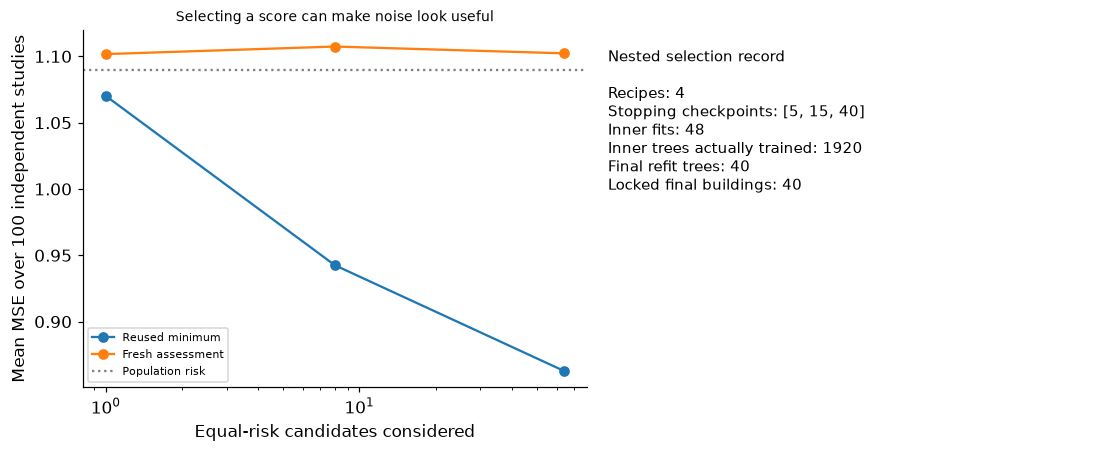

In [3]:
gr=np.random.default_rng(SEED+200);studies=[]
for study in range(100):
    vy=gr.normal(size=40);fy=gr.normal(size=200);vp=gr.normal(scale=.3,size=(40,64));fp=gr.normal(scale=.3,size=(200,64));scores=np.mean((vp-vy[:,None])**2,axis=0)
    for count in [1,8,64]:
        chosen=int(np.argmin(scores[:count]));studies.append({'study':study,'candidates':count,'selected_index':chosen,'reused_MSE':float(scores[chosen]),'fresh_MSE':float(np.mean((fp[:,chosen]-fy)**2))})
aggregate=[]
for count in [1,8,64]:
    r=[v for v in studies if v['candidates']==count];aggregate.append({'candidates':count,'mean_reused_MSE':float(np.mean([v['reused_MSE'] for v in r])),'mean_fresh_MSE':float(np.mean([v['fresh_MSE'] for v in r])),'population_MSE_each':1.09})
assert len(studies)==300 and all(0<=r['selected_index']<r['candidates'] for r in studies);assert all(np.isfinite(r['fresh_MSE']) for r in studies)
RESULTS.update(equal_risk_studies=100,reused_assessment_records=40,fresh_assessment_records=200,equal_risk_selection_summary=aggregate,equal_risk_selection_records=studies,all_attempted_inner_recipes=specs,stopping_checkpoints_considered=checkpoints)
display(pd.DataFrame(aggregate));fig,axes=plt.subplots(1,2,figsize=(10,4))
for key,label in [('mean_reused_MSE','Reused minimum'),('mean_fresh_MSE','Fresh assessment')]:axes[0].plot([1,8,64],[r[key] for r in aggregate],'o-',label=label)
axes[0].axhline(1.09,color='.5',linestyle=':',label='Population risk');axes[0].set(xscale='log',xlabel='Equal-risk candidates considered',ylabel='Mean MSE over 100 independent studies',title='Selecting a score can make noise look useful');axes[0].legend(fontsize=7);axes[1].axis('off');axes[1].text(.02,.95,f'Nested selection record\n\nRecipes: {len(specs)}\nStopping checkpoints: {checkpoints}\nInner fits: {len(fit_audit)}\nInner trees actually trained: {len(fit_audit)*40}\nFinal refit trees: {n}\nLocked final buildings: 40',va='top',fontsize=10);plt.show()


In [4]:
summary={'example_id':'code_187','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual grouped inner selection of depth rate and stopping checkpoint', 'outer evaluation with source-only preprocessing and executed fixed-budget refits', 'whole-source inner selection followed by locked independent final assessment', 'repeated equal-risk predictor selection showing reused-score optimism', 'nested information-boundary diagram with actual building counts'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual grouped inner selection of depth rate and stopping checkpoint", "outer evaluation with source-only preprocessing and executed fixed-budget refits", "whole-source inner selection followed by locked independent final assessment", "repeated equal-risk predictor selection showing reused-score optimism", "nested information-boundary diagram with actual building counts"], "elapsed_seconds": 1.023, "example_id": "code_187", "hardware": "Darwin arm64 CPU", "results": {"all_attempted_inner_recipes": [{"depth": 2, "rate": 0.05}, {"depth": 2, "rate": 0.15}, {"depth": 5, "rate": 0.05}, {"depth": 5, "rate": 0.15}], "all_source_inner_mean_table": [[1.4898937659983857, 1.2963745818479073, 1.1557606614841325], [1.30535829861165, 1.129305170489442, 0.9738515053575304], [1.4179577915924495, 1.192873920327976, 1.0417858017979136], [1.197062544931343, 1.022444712002174, 0.856795546892598]], "all_source_inner_selected_MSE": 0.856795546892598, "equal